In [ ]:
# Task 1: Backpropagation — Manual MLP in PyTorch
#
# Requirements:
# (a) Implement Linear, ReLU, and softmax cross-entropy with explicit forward/backward.
# (b) Compare manual gradients against autograd and centred finite differences.
# (c) Train on flattened CIFAR-10 with SGD; plot loss and report validation accuracy.
# (d) Compare per-layer gradient norms at initialization for 10-layer sigmoid and ReLU MLPs.

In [ ]:
import math
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

seed = 40
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", device)

PyTorch: 2.11.0+cu130
Device: cuda


In [ ]:
class Linear:
    """Fully connected layer with explicit forward and backward."""
    def __init__(self, in_features, out_features, generator=None, dtype=torch.float32):
        self.W = torch.randn(in_features, out_features, generator=generator, dtype=dtype) * math.sqrt(2.0 / in_features)
        self.b = torch.zeros(out_features, dtype=dtype)
        self.dW = torch.zeros_like(self.W)
        self.db = torch.zeros_like(self.b)
        self.x = None

    def forward(self, x):
        self.x = x
        return x @ self.W + self.b

    def backward(self, grad_out):
        self.dW = self.x.T @ grad_out
        self.db = grad_out.sum(dim=0)
        grad_x = grad_out @ self.W.T
        return grad_x

    def parameters(self):
        return [(self.W, self.dW), (self.b, self.db)]


class ReLU:
    """ReLU activation with explicit backward."""
    def __init__(self):
        self.x = None

    def forward(self, x):
        self.x = x
        return torch.clamp(x, min=0)

    def backward(self, grad_out):
        return grad_out * (self.x > 0).to(grad_out.dtype)


class Sigmoid:
    """Sigmoid activation, used in Part D."""
    def __init__(self):
        self.out = None

    def forward(self, x):
        self.out = torch.sigmoid(x)
        return self.out

    def backward(self, grad_out):
        return grad_out * self.out * (1 - self.out)


class SoftmaxCrossEntropy:
    """Numerically stable softmax cross-entropy with explicit gradient."""
    def __init__(self):
        self.probs = None
        self.targets = None

    def forward(self, logits, targets):
        # Shift logits for numerical stability.
        shifted = logits - logits.max(dim=1, keepdim=True).values
        exp_logits = torch.exp(shifted)
        self.probs = exp_logits / exp_logits.sum(dim=1, keepdim=True)
        self.targets = targets
        n = logits.shape[0]
        chosen = self.probs[torch.arange(n, device=logits.device), targets]
        return -torch.log(chosen.clamp_min(1e-12)).mean()

    def backward(self):
        grad = self.probs.clone()
        n = grad.shape[0]
        grad[torch.arange(n, device=grad.device), self.targets] -= 1
        return grad / n

In [ ]:
class ManualMLP:
    def __init__(self, dimensions, activation="relu", seed=seed):
        assert activation in ("relu", "sigmoid")
        gen = torch.Generator().manual_seed(seed)
        self.layers = []
        for i in range(len(dimensions) - 1):
            self.layers.append(Linear(dimensions[i], dimensions[i + 1], generator=gen))
            if i < len(dimensions) - 2:
                self.layers.append(ReLU() if activation == "relu" else Sigmoid())
        self.loss_fn = SoftmaxCrossEntropy()

    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x

    def loss(self, logits, targets):
        return self.loss_fn.forward(logits, targets)

    def backward(self):
        grad = self.loss_fn.backward()
        for layer in reversed(self.layers):
            grad = layer.backward(grad)
        return grad

    def parameters(self):
        params = []
        for layer in self.layers:
            if isinstance(layer, Linear):
                params.extend(layer.parameters())
        return params

    @torch.no_grad()
    def step(self, learning_rate):
        for param, grad in self.parameters():
            param -= learning_rate * grad

    @torch.no_grad()
    def predict(self, x):
        return self.forward(x).argmax(dim=1)

# (b). Gradient Comparision
###  Compare gradients for a small network with:
### 1. The manual backward implementation.
### 2. PyTorch autograd.
### 3. Centred finite differences: `[L(theta + eps) - L(theta - eps)] / (2 eps)`.
###
### Relative error is `||g_manual - g_reference|| / max(||g_manual||, ||g_reference||, tiny)`.

In [ ]:
def relative_error(a, b):
    denom = max(torch.linalg.vector_norm(a).item(),
                torch.linalg.vector_norm(b).item(), 1e-15)
    return torch.linalg.vector_norm(a - b).item() / denom


def gradient_check():
    torch.manual_seed(7)
    dtype = torch.float64
    x = torch.randn(5, 4, dtype=dtype)
    targets = torch.tensor([0, 2, 1, 2, 0], dtype=torch.long)

    # One linear layer makes it straightforward to check every parameter.
    W = (torch.randn(4, 3, dtype=dtype) * 0.2).requires_grad_()
    b = (torch.randn(3, dtype=dtype) * 0.1).requires_grad_()

    # Autograd reference
    logits_auto = x @ W + b
    loss_auto = torch.nn.functional.cross_entropy(logits_auto, targets)
    gW_auto, gb_auto = torch.autograd.grad(loss_auto, (W, b))

    # Manual forward/backward
    layer = Linear(4, 3, dtype=dtype)
    layer.W = W.detach().clone()
    layer.b = b.detach().clone()
    manual_loss_fn = SoftmaxCrossEntropy()
    logits_manual = layer.forward(x)
    loss_manual = manual_loss_fn.forward(logits_manual, targets)
    grad_logits = manual_loss_fn.backward()
    _ = layer.backward(grad_logits)
    gW_manual, gb_manual = layer.dW.clone(), layer.db.clone()

    # Centred finite differences for each element of W and b.
    eps = 1e-6
    def scalar_loss(Wv, bv):
        return torch.nn.functional.cross_entropy(x @ Wv + bv, targets).item()

    gW_fd = torch.zeros_like(W)
    for idx in np.ndindex(*W.shape):
        W_plus, W_minus = W.detach().clone(), W.detach().clone()
        W_plus[idx] += eps
        W_minus[idx] -= eps
        gW_fd[idx] = (scalar_loss(W_plus, b.detach()) -
                      scalar_loss(W_minus, b.detach())) / (2 * eps)

    gb_fd = torch.zeros_like(b)
    for idx in range(b.numel()):
        b_plus, b_minus = b.detach().clone(), b.detach().clone()
        b_plus[idx] += eps
        b_minus[idx] -= eps
        gb_fd[idx] = (scalar_loss(W.detach(), b_plus) -
                      scalar_loss(W.detach(), b_minus)) / (2 * eps)

    results = [
        ("W: manual vs autograd", relative_error(gW_manual, gW_auto),
         torch.allclose(gW_manual, gW_auto, atol=1e-10, rtol=1e-8)),
        ("b: manual vs autograd", relative_error(gb_manual, gb_auto),
         torch.allclose(gb_manual, gb_auto, atol=1e-10, rtol=1e-8)),
        ("W: manual vs finite difference", relative_error(gW_manual, gW_fd),
         torch.allclose(gW_manual, gW_fd, atol=1e-7, rtol=1e-5)),
        ("b: manual vs finite difference", relative_error(gb_manual, gb_fd),
         torch.allclose(gb_manual, gb_fd, atol=1e-7, rtol=1e-5)),
    ]
    print(f"Manual loss: {loss_manual.item():.12f} | Autograd loss: {loss_auto.item():.12f}")
    print(f"{'Comparison':38s} {'Relative error':>16s} {'torch.allclose':>16s}")
    for name, err, close in results:
        print(f"{name:38s} {err:16.3e} {str(close):>16s}")
    assert all(row[2] for row in results), "At least one gradient check failed."
    print("\nAll gradient checks passed.")

gradient_check()

Manual loss: 1.206670071059 | Autograd loss: 1.206670071059
Comparison                               Relative error   torch.allclose
W: manual vs autograd                         6.149e-17             True
b: manual vs autograd                         2.340e-16             True
W: manual vs finite difference                2.705e-10             True
b: manual vs finite difference                9.050e-10             True

All gradient checks passed.


# (c) Load CIFAR-10 and flatten images and train the manual MLP using SGD
### CIFAR-10 images have shape `3 × 32 × 32`; flattening gives 3072 features.

In [ ]:
from google.colab import drive
import os

# Mount Google Drive
drive.mount('/content/drive')

# Configuration
BATCH_SIZE = 256
VAL_SIZE = 5000
EPOCHS = 15
LEARNING_RATE = 0.05
HIDDEN_DIMS = [512, 256]

# Store the dataset in Google Drive
DATA_ROOT = "/content/drive/MyDrive/datasets/cifar10"
os.makedirs(DATA_ROOT, exist_ok=True)

transform = transforms.ToTensor()

# Download only if the dataset is not already available
train_full = datasets.CIFAR10(
    root=DATA_ROOT,
    train=True,
    download=not os.path.exists(
        os.path.join(DATA_ROOT, "cifar-10-batches-py", "data_batch_1")
    ),
    transform=transform
)

test_dataset = datasets.CIFAR10(
    root=DATA_ROOT,
    train=False,
    download=not os.path.exists(
        os.path.join(DATA_ROOT, "cifar-10-batches-py", "test_batch")
    ),
    transform=transform
)

# Train-validation split
train_size = len(train_full) - VAL_SIZE

train_dataset, val_dataset = random_split(
    train_full,
    [train_size, VAL_SIZE],
    generator=torch.Generator().manual_seed(seed)
)

# Data loaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=512,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=512,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

class_names = train_full.classes

print("Classes:", class_names)
print(f"Train: {len(train_dataset)} | Validation: {len(val_dataset)} | Test: {len(test_dataset)}")
print(f"Dataset location: {DATA_ROOT}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


100%|██████████| 170M/170M [1:01:18<00:00, 46.4kB/s]


Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Train: 45000 | Validation: 5000 | Test: 10000
Dataset location: /content/drive/MyDrive/datasets/cifar10


In [ ]:
def flatten_images(images):
    return images.reshape(images.shape[0], -1)

def evaluate(model, loader):
    correct, total, total_loss = 0, 0, 0.0
    for images, labels in loader:
        x = flatten_images(images).to(device)
        y = labels.to(device)
        logits = model.forward(x)
        # Evaluation loss can use the model's loss object; no backward is called.
        loss = model.loss(logits, y)
        total_loss += loss.item() * y.shape[0]
        correct += (logits.argmax(dim=1) == y).sum().item()
        total += y.shape[0]
    return total_loss / total, 100.0 * correct / total

model = ManualMLP([3072] + HIDDEN_DIMS + [10], activation="relu", seed=seed)
model.layers = [
    layer for layer in model.layers
]  # keep explicit for readability
# Move all parameters to the selected device.
for layer in model.layers:
    if isinstance(layer, Linear):
        layer.W = layer.W.to(device)
        layer.b = layer.b.to(device)
        layer.dW = layer.dW.to(device)
        layer.db = layer.db.to(device)

history = {"train_loss": [], "val_loss": [], "val_accuracy": []}

for epoch in range(1, EPOCHS + 1):
    running_loss, seen = 0.0, 0
    for images, labels in train_loader:
        x = flatten_images(images).to(device, non_blocking=True)
        y = labels.to(device, non_blocking=True)

        logits = model.forward(x)
        loss = model.loss(logits, y)
        model.backward()
        model.step(LEARNING_RATE)

        running_loss += loss.item() * y.shape[0]
        seen += y.shape[0]

    train_loss = running_loss / seen
    val_loss, val_acc = evaluate(model, val_loader)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_acc)
    print(f"Epoch {epoch:02d}/{EPOCHS} | train loss {train_loss:.4f} | "
          f"val loss {val_loss:.4f} | val accuracy {val_acc:.2f}%")

Epoch 01/15 | train loss 2.0020 | val loss 1.9581 | val accuracy 31.22%
Epoch 02/15 | train loss 1.8147 | val loss 1.7394 | val accuracy 37.82%
Epoch 03/15 | train loss 1.7276 | val loss 1.6803 | val accuracy 39.84%
Epoch 04/15 | train loss 1.6704 | val loss 1.7072 | val accuracy 38.92%
Epoch 05/15 | train loss 1.6309 | val loss 1.6666 | val accuracy 40.90%
Epoch 06/15 | train loss 1.5868 | val loss 1.5554 | val accuracy 44.56%
Epoch 07/15 | train loss 1.5637 | val loss 1.6102 | val accuracy 41.20%
Epoch 08/15 | train loss 1.5346 | val loss 1.5197 | val accuracy 46.72%
Epoch 09/15 | train loss 1.5057 | val loss 1.5482 | val accuracy 44.64%
Epoch 10/15 | train loss 1.4825 | val loss 1.5606 | val accuracy 45.10%
Epoch 11/15 | train loss 1.4664 | val loss 1.4732 | val accuracy 47.34%
Epoch 12/15 | train loss 1.4422 | val loss 1.4798 | val accuracy 47.48%
Epoch 13/15 | train loss 1.4207 | val loss 1.4876 | val accuracy 46.72%
Epoch 14/15 | train loss 1.4031 | val loss 1.4925 | val accuracy

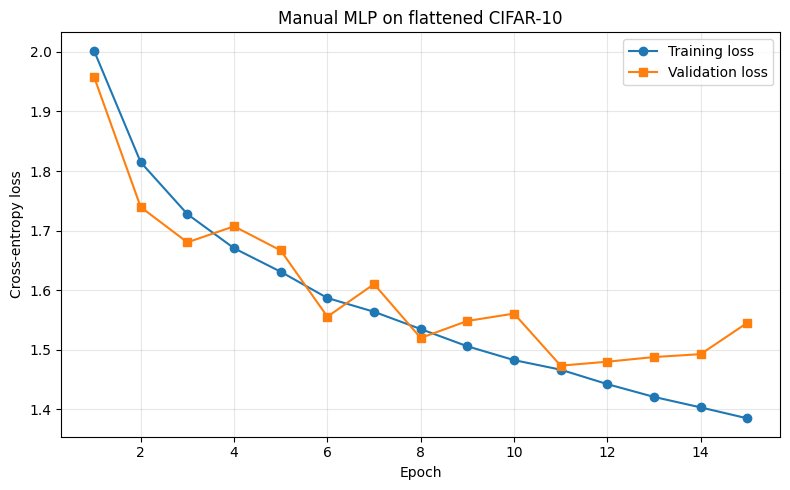

Best validation loss: 1.4732 at epoch 11
Validation accuracy at that epoch: 47.34%
Final validation accuracy: 45.68%


In [ ]:
epochs = np.arange(1, EPOCHS + 1)
plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_loss"], marker="o", label="Training loss")
plt.plot(epochs, history["val_loss"], marker="s", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Manual MLP on flattened CIFAR-10")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

best_epoch = int(np.argmin(history["val_loss"])) + 1
best_val_acc = history["val_accuracy"][best_epoch - 1]
print(f"Best validation loss: {min(history['val_loss']):.4f} at epoch {best_epoch}")
print(f"Validation accuracy at that epoch: {best_val_acc:.2f}%")
print(f"Final validation accuracy: {history['val_accuracy'][-1]:.2f}%")

#  7. Ten-layer gradient-flow experiment at initialization
### Here, "10-layer MLP" means 10 linear layers, with an activation after the first
### 9 linear layers and 10 output logits. We use the same input batch and identical
### weight tensors for the sigmoid and ReLU runs so that activation is the main change.
###
### The loss is evaluated on a fixed random batch of CIFAR-like flattened inputs and
### random class labels. This experiment measures gradient norms at initialization,
### not training performance.

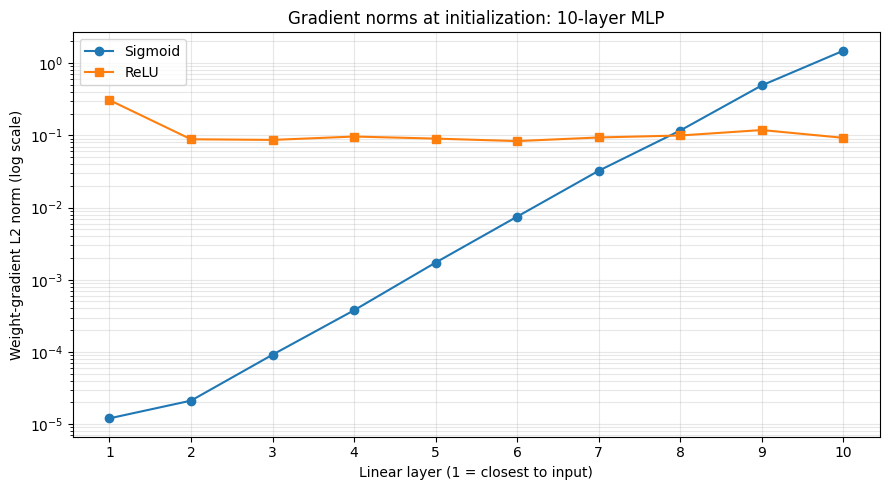

Layer | Sigmoid gradient norm | ReLU gradient norm
    1 |          1.204175e-05 |        3.075741e-01
    2 |          2.117856e-05 |        8.823468e-02
    3 |          9.158640e-05 |        8.644616e-02
    4 |          3.780684e-04 |        9.624178e-02
    5 |          1.729561e-03 |        9.011911e-02
    6 |          7.487157e-03 |        8.327682e-02
    7 |          3.230859e-02 |        9.347099e-02
    8 |          1.166793e-01 |        9.950428e-02
    9 |          4.912857e-01 |        1.184414e-01
   10 |          1.485902e+00 |        9.238663e-02


In [ ]:
def make_deep_mlp(input_dim=3072, width=128, num_linear_layers=10, activation="relu", seed=123):
    assert activation in ("relu", "sigmoid")
    gen = torch.Generator().manual_seed(seed)
    dims = [input_dim] + [width] * (num_linear_layers - 1) + [10]
    # For the gradient-flow comparison, use the same weights in both models.
    linears = []
    for i in range(len(dims) - 1):
        layer = Linear(dims[i], dims[i + 1], generator=gen)
        # Xavier initialization is a common neutral starting point for comparing
        # sigmoid and ReLU; identical tensors are copied between activation runs.
        fan_in, fan_out = dims[i], dims[i + 1]
        layer.W = torch.randn(dims[i], dims[i + 1], generator=gen) * math.sqrt(2.0 / (fan_in + fan_out))
        layer.b = torch.zeros(dims[i + 1])
        linears.append(layer)
    layers = []
    for i, linear in enumerate(linears):
        layers.append(linear)
        if i < len(linears) - 1:
            layers.append(ReLU() if activation == "relu" else Sigmoid())
    return layers

def deep_gradient_norms(layers, x, targets):
    logits = x
    for layer in layers:
        logits = layer.forward(logits)
    loss_fn = SoftmaxCrossEntropy()
    loss = loss_fn.forward(logits, targets)
    grad = loss_fn.backward()
    for layer in reversed(layers):
        grad = layer.backward(grad)
    norms = []
    for layer in layers:
        if isinstance(layer, Linear):
            norms.append(torch.linalg.vector_norm(layer.dW).item())
    return norms, loss.item()

torch.manual_seed(2026)
x_deep = torch.randn(128, 3072)
targets_deep = torch.randint(0, 10, (128,))

# Create sigmoid layers and copy the exact same initialized weights to ReLU layers.
sigmoid_layers = make_deep_mlp(activation="sigmoid", seed=123)
relu_layers = make_deep_mlp(activation="relu", seed=123)

sigmoid_norms, sigmoid_loss = deep_gradient_norms(sigmoid_layers, x_deep, targets_deep)
relu_norms, relu_loss = deep_gradient_norms(relu_layers, x_deep, targets_deep)

layer_ids = np.arange(1, 11)
plt.figure(figsize=(9, 5))
plt.semilogy(layer_ids, np.maximum(sigmoid_norms, 1e-20), marker="o", label="Sigmoid")
plt.semilogy(layer_ids, np.maximum(relu_norms, 1e-20), marker="s", label="ReLU")
plt.xlabel("Linear layer (1 = closest to input)")
plt.ylabel("Weight-gradient L2 norm (log scale)")
plt.title("Gradient norms at initialization: 10-layer MLP")
plt.xticks(layer_ids)
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print("Layer | Sigmoid gradient norm | ReLU gradient norm")
for i, (sn, rn) in enumerate(zip(sigmoid_norms, relu_norms), start=1):
    print(f"{i:5d} | {sn:21.6e} | {rn:19.6e}")

# ### Explanation
# - **Sigmoid can cause vanishing gradients.** Its derivative is `sigmoid(x) * (1 - sigmoid(x))`,
#   which is at most 0.25 and becomes close to zero when activations saturate. During
#   backpropagation, derivatives from many layers are multiplied together, so gradients
#   reaching early layers can become very small.
# - **ReLU usually preserves stronger gradients for positive activations.** Its derivative
#   is 1 for positive inputs and 0 for negative inputs. This avoids the repeated
#   multiplication by small sigmoid derivatives, although inactive ReLU units can still
#   block gradients and gradients may still shrink or grow depending on initialization.
# - The exact curves depend on the random seed, width, initialization, input batch, and labels.
#   The experiment is evidence for this initialization, not a universal guarantee.

# ## 8. Optional: evaluate on the official CIFAR-10 test set
# Do this after model choices are complete. The validation set should be used for
# hyperparameter decisions; the test set is best reserved for final reporting.

In [ ]:
test_loss, test_acc = evaluate(model, test_loader)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.2f}%")

Test loss: 1.5448
Test accuracy: 46.11%


# ## Report checklist
# Include these outputs in your submission:
# 1. The relative errors and `torch.allclose` results from Part B.
# 2. The training/validation loss plot and final/best validation accuracy from Part C.
# 3. The per-layer gradient norm plot and printed values from Part D.
# 4. The explanation that sigmoid derivatives can repeatedly shrink gradients, while ReLU
#    generally improves gradient flow but can have inactive units.